In [1]:
import scanpy as sc
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances, manhattan_distances
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Figuring things out

In [2]:
adata = sc.read_h5ad("../data/suberites_domuncula_cytotrace_SUB4.h5ad")

In [3]:
adata

AnnData object with n_obs × n_vars = 2662 × 20350
    obs: 'n_genes_by_counts', 'total_counts', 'clusters', 'ct_score', 'ct_pseudotime', 'ct_num_exp_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std', 'ct_gene_corr', 'ct_correlates'
    uns: 'clusters_colors', 'clusters_sizes', 'ct_params', 'hvg', 'leiden', 'log1p', 'neighbors', 'paga', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'Ms', 'Mu', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

In [4]:
# Add cluster name mapping
clusters_names = {
    '0': 'skin', '1': 'transition', '2': 'skeletal', 
    '3': 'skeletal', '5': 'stem', '6': 'digestion',
    '8': 'maybe digestion', '12': 'choanocytes'
}

# Map cluster names to clusters and add as a new column in 'number: name' format
adata.obs['clusters_name'] = adata.obs['clusters'].map(
    lambda x: f"{x}: {clusters_names[x]}" if x in clusters_names else x
)

In [5]:
# give an id number to each gene
adata.obs['id'] = range(adata.n_obs)

In [6]:
adata.obs.head()

,n_genes_by_counts,total_counts,clusters,ct_score,ct_pseudotime,ct_num_exp_genes,clusters_name,id
AAACCCAAGGACAGCT-1,259,740.0,3,0.186067,0.813933,1087,3: skeletal,0
AAACCCAAGGGTTTCT-1,1049,2118.0,0,0.366733,0.633267,4256,0: skin,1
AAACCCACAAATGGTA-1,882,4172.0,2,0.155237,0.844763,1942,2: skeletal,2
AAACCCATCGAGAAGC-1,819,2078.0,8,0.360626,0.639374,3958,8: maybe digestion,3
AAACCCATCTTGTTAC-1,488,1972.0,3,0.178127,0.821873,1190,3: skeletal,4


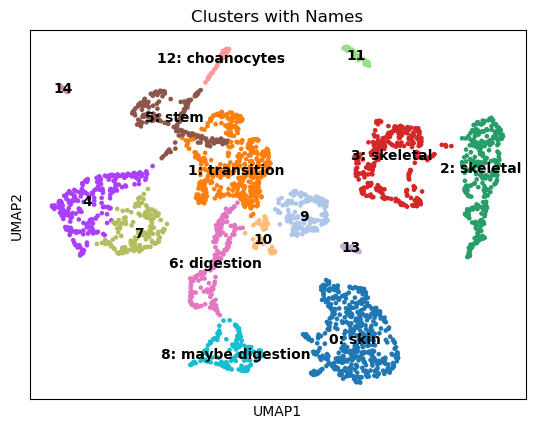

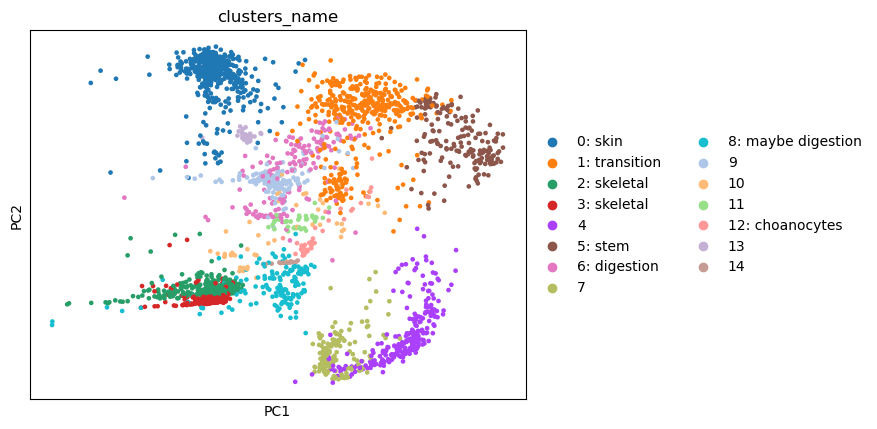

In [7]:
sc.pl.umap(adata,color="clusters_name", legend_loc='on data', title='Clusters with Names')
sc.pl.pca(adata,color="clusters_name")

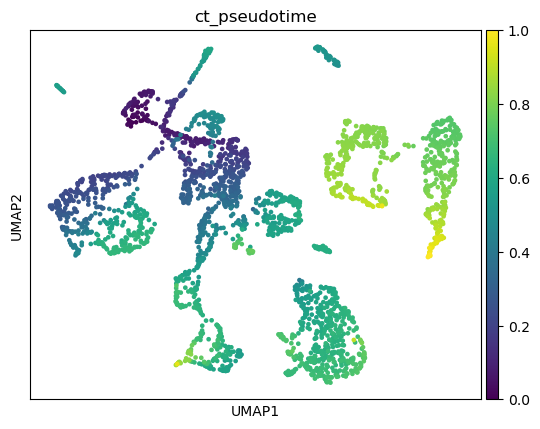

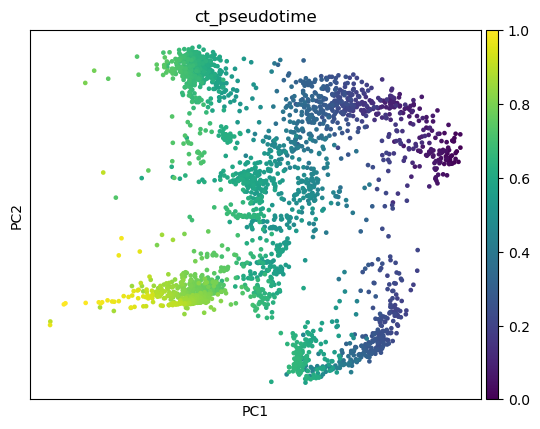

In [8]:
sc.pl.umap(adata,color="ct_pseudotime")
sc.pl.pca(adata,color="ct_pseudotime")

# Silhouette Score Mapping

In [9]:
silhouette_scores = silhouette_samples(adata.obsm['X_pca'], adata.obs['clusters'])
#silhouette_scores = silhouette_samples(adata.obsm['X_umap'], adata.obs['clusters'])

adata.obs['silhouette_score'] = silhouette_scores

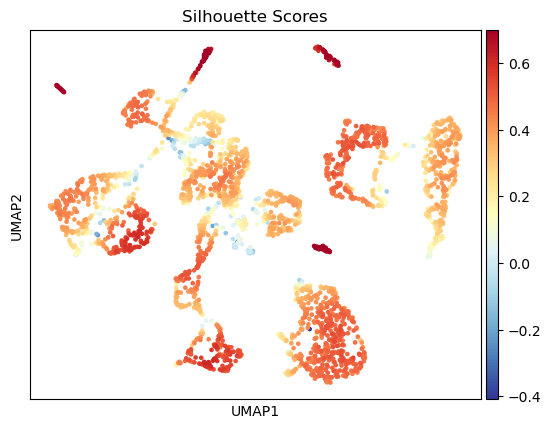

In [10]:
sc.pl.umap(adata, color='silhouette_score', cmap='RdYlBu_r', 
           title='Silhouette Scores', vmax=0.7)

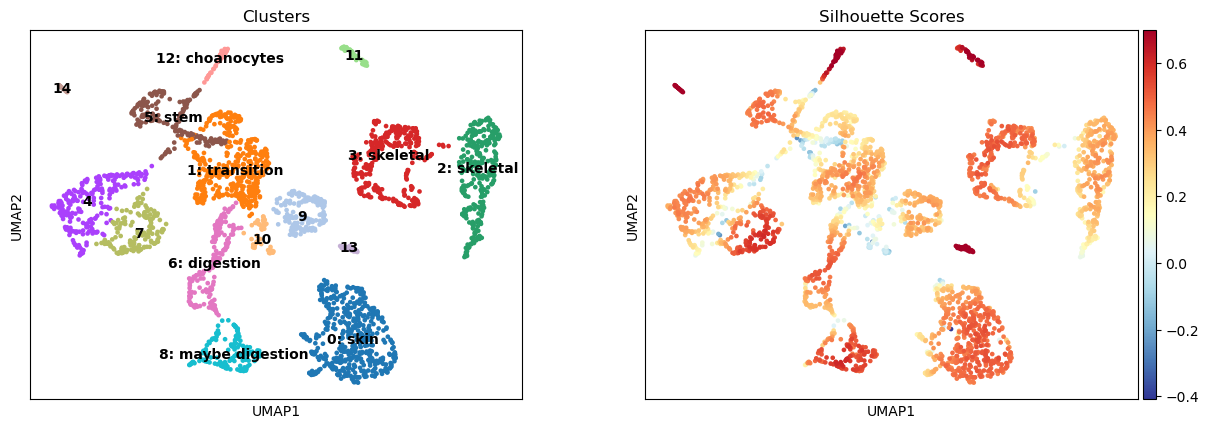

In [11]:
sc.pl.umap(adata, color=['clusters_name', 'silhouette_score'], 
           ncols=2, cmap='RdYlBu_r', legend_loc='on data', 
           title=['Clusters', 'Silhouette Scores'], vmax=0.7)

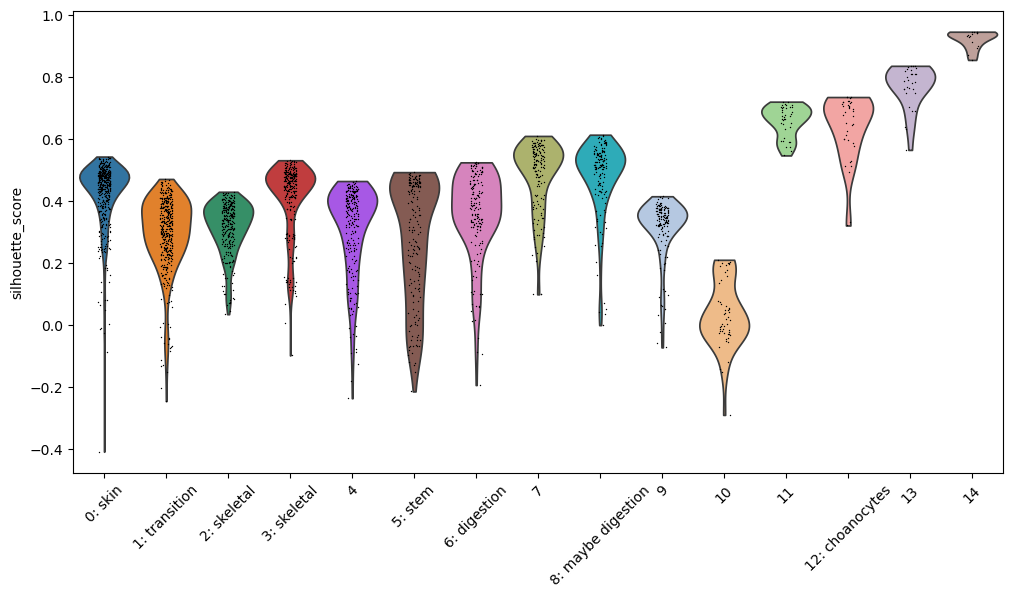

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
sc.pl.violin(adata, keys='silhouette_score', groupby='clusters_name', 
             rotation=45, ax=ax)

plt.show()

# Extractig Swing States and comparing similarity

In [13]:
# Analyze swing states from cluster 1
origin_cluster = '5'
swing_states = adata[(adata.obs['silhouette_score'] <= 0.0) & (adata.obs['clusters'] == origin_cluster)]
#swing_states = adata[(adata.obs['silhouette_score'] <= 0)]

print(f"Amount of swing state cells: {len(swing_states)}")
print(f"These cells have negative silhouette scores, indicating uncertainty in cluster assignment")

# Basic info about swing states
print(f"\nSwing states silhouette score range: {swing_states.obs['silhouette_score'].min():.3f} to {swing_states.obs['silhouette_score'].max():.3f}")
print(f"Average pseudotime: {swing_states.obs['ct_pseudotime'].mean():.3f}")

# Display all swing state cells as a table (show all rows)

pd.set_option('display.max_rows', None)
swing_states.obs[['id', 'clusters_name', 'silhouette_score', 'ct_pseudotime']].sort_values(by=['clusters_name', 'silhouette_score']).head(10)

Amount of swing state cells: 23
These cells have negative silhouette scores, indicating uncertainty in cluster assignment

Swing states silhouette score range: -0.215 to -0.000
Average pseudotime: 0.115


,id,clusters_name,silhouette_score,ct_pseudotime
TGGTTAGTCCGACATA-1,2424,5: stem,-0.215279,0.230724
TAACCAGTCGCTGTCT-1,1855,5: stem,-0.153031,0.241080
TCGTCCACAACCTATG-1,2197,5: stem,-0.129847,0.102740
GAAGTAAAGATCGCTT-1,1261,5: stem,-0.122345,0.096258
ACTGATGGTCTTACTT-1,246,5: stem,-0.119548,0.104595
ACGATGTGTACGACAG-1,193,5: stem,-0.097485,0.089526
GTGTGATGTGCGTCGT-1,1787,5: stem,-0.090558,0.089783
CGGAGAACAAGGCGTA-1,995,5: stem,-0.080819,0.085719
CCAATTTCAAGAGGTC-1,798,5: stem,-0.072475,0.082759
CATCGTCAGTATGAAC-1,747,5: stem,-0.070149,0.086203


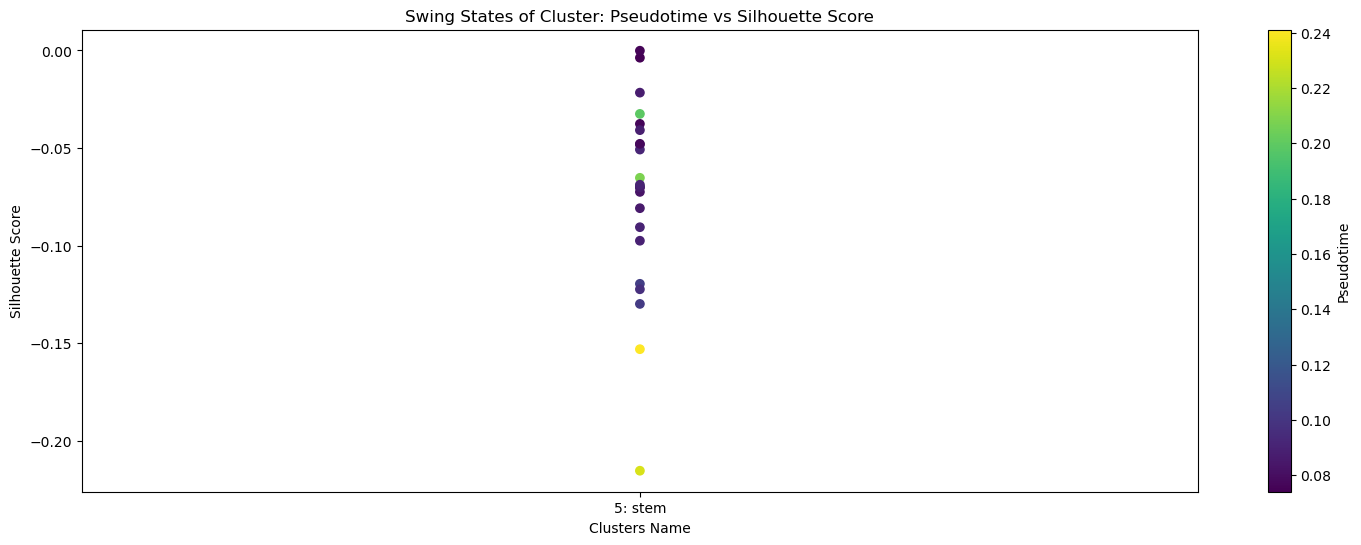

In [14]:
plt.figure(figsize=(18,6))
plt.scatter(swing_states.obs['clusters_name'], swing_states.obs['silhouette_score'], c=swing_states.obs['ct_pseudotime'], cmap='viridis')
plt.colorbar(label='Pseudotime')
plt.xlabel('Clusters Name')
plt.ylabel('Silhouette Score')
plt.title(f'Swing States of Cluster: Pseudotime vs Silhouette Score')
plt.show()

Analyzing 23 swing state cells
Comparing to 15 clusters
Calculating distances to cluster centroids...
Calculating distances to nearest cells in each cluster (excluding self)...
Creating centroid distances heatmap...
Creating nearest cell distances heatmap...


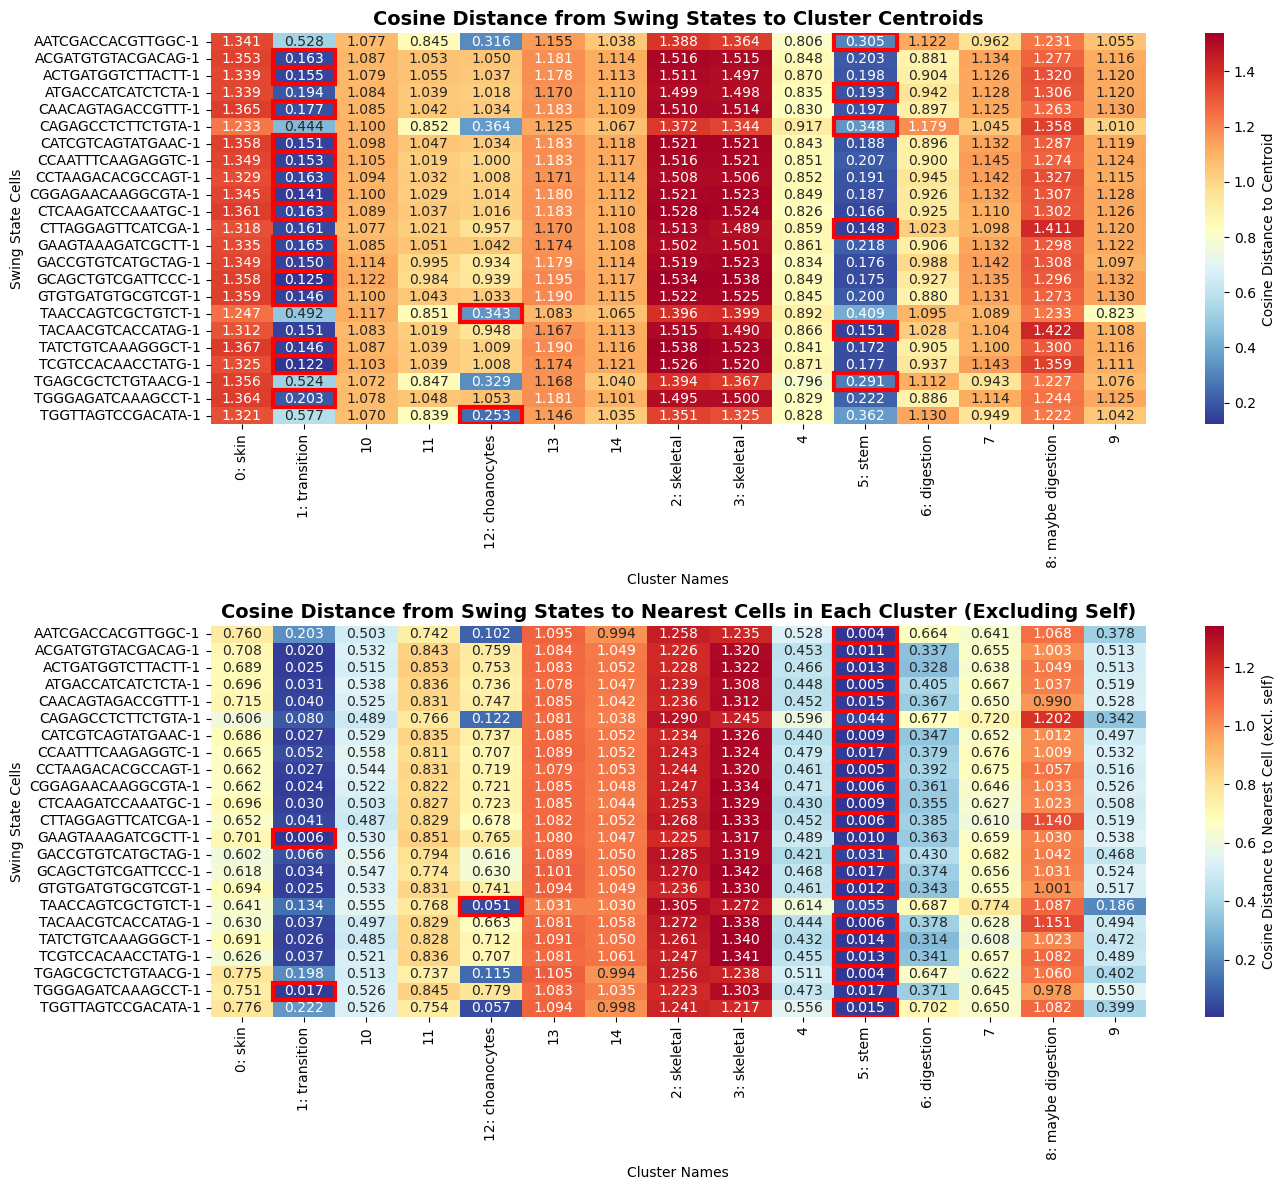


DISTANCE COMPARISON SUMMARY
           cell_id current_cluster closest_centroid centroid_distance closest_nearest_cell nearest_distance  same_prediction
AATCGACCACGTTGGC-1         5: stem          5: stem             0.305              5: stem            0.004             True
ACGATGTGTACGACAG-1         5: stem    1: transition             0.163              5: stem            0.011            False
ACTGATGGTCTTACTT-1         5: stem    1: transition             0.155              5: stem            0.013            False
ATGACCATCATCTCTA-1         5: stem          5: stem             0.193              5: stem            0.005             True
CAACAGTAGACCGTTT-1         5: stem    1: transition             0.177              5: stem            0.015            False
CAGAGCCTCTTCTGTA-1         5: stem          5: stem             0.348              5: stem            0.044             True
CATCGTCAGTATGAAC-1         5: stem    1: transition             0.151              5: stem      

In [15]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_distances
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get swing states coordinates
swing_pca = swing_states.obsm['X_pca']
print(f"Analyzing {len(swing_states)} swing state cells")

# Get all clusters and their names
all_clusters = sorted(adata.obs['clusters'].unique())
cluster_names = {}
for cluster in all_clusters:
    # Get cluster name if available, otherwise use cluster number
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    if 'clusters_name' in adata.obs.columns:
        name = cluster_cells.obs['clusters_name'].iloc[0] if len(cluster_cells) > 0 else f"Cluster_{cluster}"
    else:
        name = f"Cluster_{cluster}"
    cluster_names[cluster] = name

print(f"Comparing to {len(all_clusters)} clusters")

# 1. CALCULATE DISTANCES TO CLUSTER CENTROIDS
print("Calculating distances to cluster centroids...")
centroid_distances = []

# Get cluster centroids
cluster_centroids = {}
for cluster in all_clusters:
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    centroid = np.mean(cluster_cells.obsm['X_pca'], axis=0)
    cluster_centroids[cluster] = centroid

for i, swing_cell_idx in enumerate(swing_states.obs_names):
    swing_coord = swing_pca[i].reshape(1, -1)
    
    cell_distances = {'cell_id': swing_cell_idx}
    
    for cluster in all_clusters:
        centroid = cluster_centroids[cluster].reshape(1, -1)
        cosine_dist = cosine_distances(swing_coord, centroid)[0][0]
        cell_distances[cluster_names[cluster]] = cosine_dist
    
    centroid_distances.append(cell_distances)

centroid_df = pd.DataFrame(centroid_distances).set_index('cell_id')

# 2. CALCULATE DISTANCES TO NEAREST CELLS IN EACH CLUSTER (EXCLUDING SELF)
print("Calculating distances to nearest cells in each cluster (excluding self)...")
nearest_distances = []

for i, swing_cell_idx in enumerate(swing_states.obs_names):
    swing_coord = swing_pca[i].reshape(1, -1)
    swing_current_cluster = swing_states.obs.loc[swing_cell_idx, 'clusters']
    
    cell_distances = {'cell_id': swing_cell_idx}
    
    for cluster in all_clusters:
        cluster_cells = adata[adata.obs['clusters'] == cluster]
        
        # If this is the swing cell's own cluster, exclude the swing cell itself
        if cluster == swing_current_cluster:
            cluster_cells = cluster_cells[cluster_cells.obs_names != swing_cell_idx]
        
        if len(cluster_cells) == 0:
            # If no cells left in cluster after excluding self, set high distance
            cell_distances[cluster_names[cluster]] = 1.0  # Max cosine distance
        else:
            cluster_coords = cluster_cells.obsm['X_pca']
            
            # Calculate distances to ALL remaining cells in this cluster
            distances_to_cluster = cosine_distances(swing_coord, cluster_coords)[0]
            
            # Take the minimum distance (closest cell, excluding self)
            min_distance = np.min(distances_to_cluster)
            cell_distances[cluster_names[cluster]] = min_distance
    
    nearest_distances.append(cell_distances)

nearest_df = pd.DataFrame(nearest_distances).set_index('cell_id')

# 3. CREATE HEATMAPS
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, max(12, len(swing_states)//2)))

# Heatmap 1: Distances to Cluster Centroids
print("Creating centroid distances heatmap...")
sns.heatmap(centroid_df, annot=True, fmt='.3f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Cosine Distance to Centroid'}, ax=ax1)
ax1.set_title('Cosine Distance from Swing States to Cluster Centroids', fontweight='bold', fontsize=14)
ax1.set_xlabel('Cluster Names')
ax1.set_ylabel('Swing State Cells')

# Highlight minimum distances with red borders for centroid heatmap
for i, cell_id in enumerate(centroid_df.index):
    row_data = centroid_df.iloc[i]
    min_cluster = row_data.idxmin()
    min_idx = list(centroid_df.columns).index(min_cluster)
    ax1.add_patch(plt.Rectangle((min_idx, i), 1, 1, fill=False, edgecolor='red', lw=3))

# Heatmap 2: Distances to Nearest Cells (Excluding Self)
print("Creating nearest cell distances heatmap...")
sns.heatmap(nearest_df, annot=True, fmt='.3f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Cosine Distance to Nearest Cell (excl. self)'}, ax=ax2)
ax2.set_title('Cosine Distance from Swing States to Nearest Cells in Each Cluster (Excluding Self)', fontweight='bold', fontsize=14)
ax2.set_xlabel('Cluster Names')
ax2.set_ylabel('Swing State Cells')

# Highlight minimum distances with red borders for nearest cell heatmap
for i, cell_id in enumerate(nearest_df.index):
    row_data = nearest_df.iloc[i]
    min_cluster = row_data.idxmin()
    min_idx = list(nearest_df.columns).index(min_cluster)
    ax2.add_patch(plt.Rectangle((min_idx, i), 1, 1, fill=False, edgecolor='red', lw=3))

plt.tight_layout()
plt.show()

# 4. COMPARISON SUMMARY
print("\n" + "="*100)
print("DISTANCE COMPARISON SUMMARY")
print("="*100)

comparison_data = []
for cell_id in centroid_df.index:
    current_cluster = swing_states.obs.loc[cell_id, 'clusters']
    current_cluster_name = cluster_names[current_cluster]
    
    centroid_min = centroid_df.loc[cell_id].idxmin()
    centroid_min_dist = centroid_df.loc[cell_id].min()
    
    nearest_min = nearest_df.loc[cell_id].idxmin()
    nearest_min_dist = nearest_df.loc[cell_id].min()
    
    comparison_data.append({
        'cell_id': cell_id,
        'current_cluster': current_cluster_name,
        'closest_centroid': centroid_min,
        'centroid_distance': f"{centroid_min_dist:.3f}",
        'closest_nearest_cell': nearest_min,
        'nearest_distance': f"{nearest_min_dist:.3f}",
        'same_prediction': centroid_min == nearest_min
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

same_predictions = comparison_df['same_prediction'].sum()
total_predictions = len(comparison_df)
print(f"\nAgreement between methods: {same_predictions}/{total_predictions} ({same_predictions/total_predictions*100:.1f}%)")

print(f"\nCells that should be reclassified (closest to different cluster):")
reclassify_centroid = comparison_df[comparison_df['current_cluster'] != comparison_df['closest_centroid']]
reclassify_nearest = comparison_df[comparison_df['current_cluster'] != comparison_df['closest_nearest_cell']]
print(f"Based on centroids: {len(reclassify_centroid)}/{len(comparison_df)} cells")
print(f"Based on nearest cells: {len(reclassify_nearest)}/{len(comparison_df)} cells")

Analyzing 23 swing state cells
Comparing to 15 clusters
Calculating distances to cluster centroids...
Calculating distances to nearest cells in OTHER clusters...
Creating centroid distances heatmap...
Creating nearest cell distances heatmap...


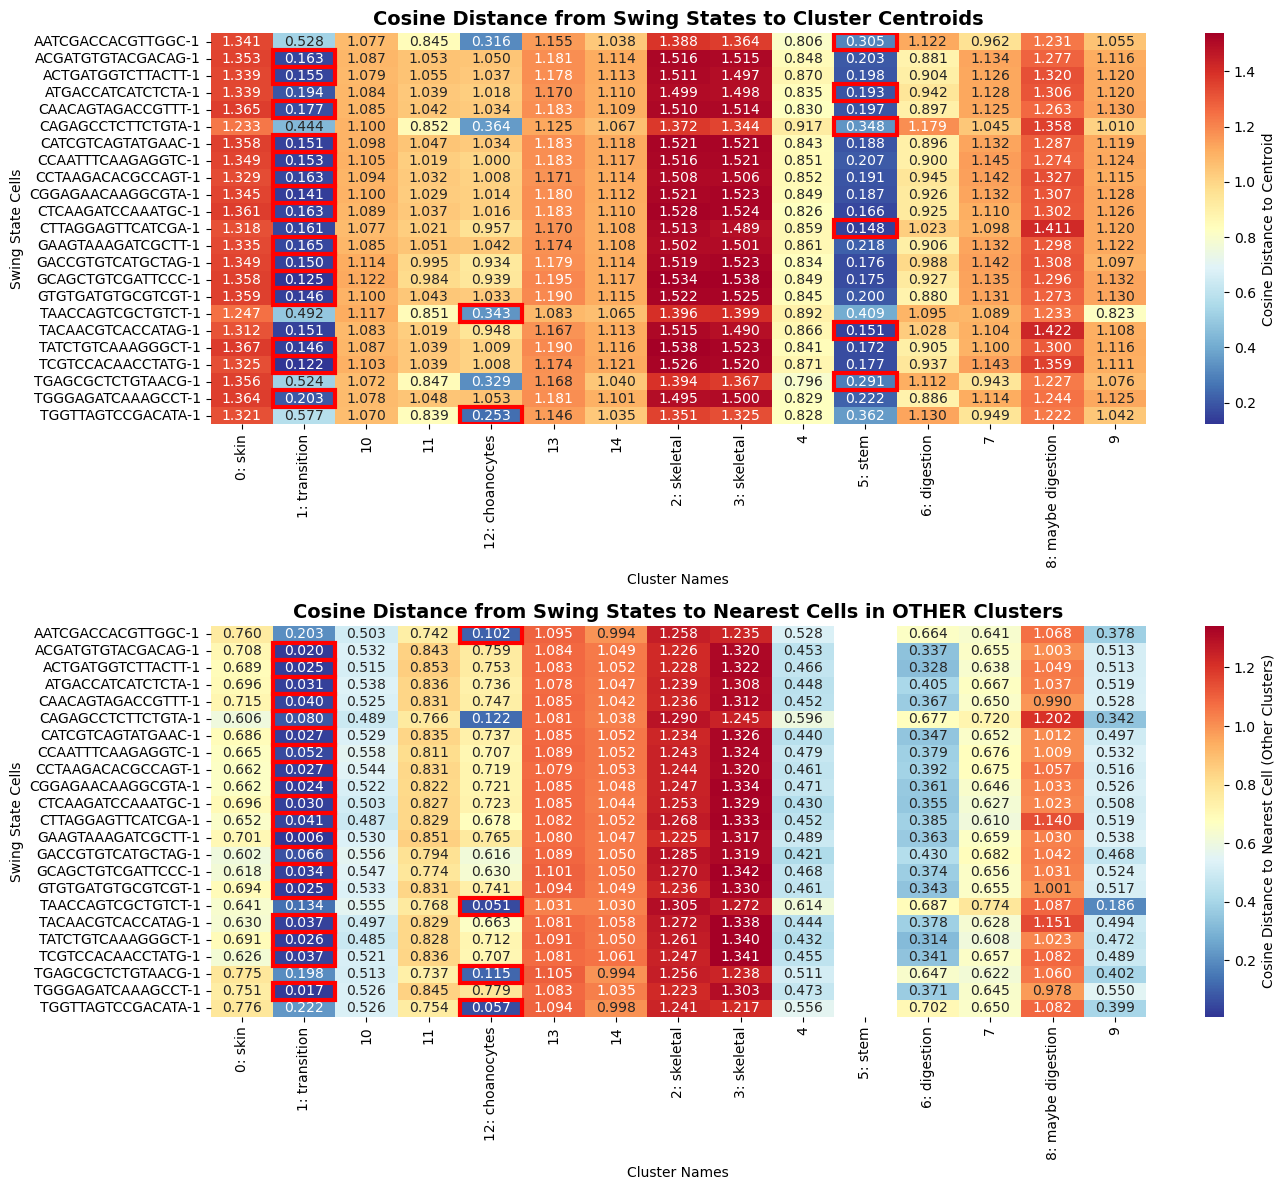


DISTANCE COMPARISON SUMMARY
           cell_id closest_centroid centroid_distance closest_nearest_cell nearest_distance  same_prediction
AATCGACCACGTTGGC-1          5: stem             0.305      12: choanocytes            0.102            False
ACGATGTGTACGACAG-1    1: transition             0.163        1: transition            0.020             True
ACTGATGGTCTTACTT-1    1: transition             0.155        1: transition            0.025             True
ATGACCATCATCTCTA-1          5: stem             0.193        1: transition            0.031            False
CAACAGTAGACCGTTT-1    1: transition             0.177        1: transition            0.040             True
CAGAGCCTCTTCTGTA-1          5: stem             0.348        1: transition            0.080            False
CATCGTCAGTATGAAC-1    1: transition             0.151        1: transition            0.027             True
CCAATTTCAAGAGGTC-1    1: transition             0.153        1: transition            0.052        

In [16]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_distances
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get swing states coordinates
swing_pca = swing_states.obsm['X_pca']
print(f"Analyzing {len(swing_states)} swing state cells")

# Get all clusters and their names
all_clusters = sorted(adata.obs['clusters'].unique())
cluster_names = {}
for cluster in all_clusters:
    # Get cluster name if available, otherwise use cluster number
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    if 'clusters_name' in adata.obs.columns:
        name = cluster_cells.obs['clusters_name'].iloc[0] if len(cluster_cells) > 0 else f"Cluster_{cluster}"
    else:
        name = f"Cluster_{cluster}"
    cluster_names[cluster] = name

print(f"Comparing to {len(all_clusters)} clusters")

# 1. CALCULATE DISTANCES TO CLUSTER CENTROIDS (same as before)
print("Calculating distances to cluster centroids...")
centroid_distances = []

# Get cluster centroids
cluster_centroids = {}
for cluster in all_clusters:
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    centroid = np.mean(cluster_cells.obsm['X_pca'], axis=0)
    cluster_centroids[cluster] = centroid

for i, swing_cell_idx in enumerate(swing_states.obs_names):
    swing_coord = swing_pca[i].reshape(1, -1)
    
    cell_distances = {'cell_id': swing_cell_idx}
    
    for cluster in all_clusters:
        centroid = cluster_centroids[cluster].reshape(1, -1)
        cosine_dist = cosine_distances(swing_coord, centroid)[0][0]
        cell_distances[cluster_names[cluster]] = cosine_dist
    
    centroid_distances.append(cell_distances)

centroid_df = pd.DataFrame(centroid_distances).set_index('cell_id')

# 2. CALCULATE DISTANCES TO NEAREST CELLS (EXCLUDING OWN CLUSTER)
print("Calculating distances to nearest cells in OTHER clusters...")
nearest_distances = []

for i, swing_cell_idx in enumerate(swing_states.obs_names):
    swing_coord = swing_pca[i].reshape(1, -1)
    
    # Get this cell's current cluster
    current_cluster = swing_states.obs.loc[swing_cell_idx, 'clusters']
    
    cell_distances = {'cell_id': swing_cell_idx}
    
    for cluster in all_clusters:
        if cluster == current_cluster:
            # For own cluster, set a high value or NaN to indicate it's excluded
            cell_distances[cluster_names[cluster]] = np.nan
        else:
            cluster_cells = adata[adata.obs['clusters'] == cluster]
            cluster_coords = cluster_cells.obsm['X_pca']
            
            # Calculate distances to ALL cells in this OTHER cluster
            distances_to_cluster = cosine_distances(swing_coord, cluster_coords)[0]
            
            # Take the minimum distance (closest cell)
            min_distance = np.min(distances_to_cluster)
            cell_distances[cluster_names[cluster]] = min_distance
    
    nearest_distances.append(cell_distances)

nearest_df = pd.DataFrame(nearest_distances).set_index('cell_id')

# 3. CREATE HEATMAPS
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, max(12, len(swing_states)//2)))

# Heatmap 1: Distances to Cluster Centroids
print("Creating centroid distances heatmap...")
sns.heatmap(centroid_df, annot=True, fmt='.3f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Cosine Distance to Centroid'}, ax=ax1)
ax1.set_title('Cosine Distance from Swing States to Cluster Centroids', fontweight='bold', fontsize=14)
ax1.set_xlabel('Cluster Names')
ax1.set_ylabel('Swing State Cells')

# Highlight minimum distances with red borders for centroid heatmap
for i, cell_id in enumerate(centroid_df.index):
    row_data = centroid_df.iloc[i]
    min_cluster = row_data.idxmin()
    min_idx = list(centroid_df.columns).index(min_cluster)
    ax1.add_patch(plt.Rectangle((min_idx, i), 1, 1, fill=False, edgecolor='red', lw=3))

# Heatmap 2: Distances to Nearest Cells (excluding own cluster)
print("Creating nearest cell distances heatmap...")
sns.heatmap(nearest_df, annot=True, fmt='.3f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Cosine Distance to Nearest Cell (Other Clusters)'}, ax=ax2)
ax2.set_title('Cosine Distance from Swing States to Nearest Cells in OTHER Clusters', fontweight='bold', fontsize=14)
ax2.set_xlabel('Cluster Names')
ax2.set_ylabel('Swing State Cells')

# Highlight minimum distances with red borders for nearest cell heatmap (excluding NaN values)
for i, cell_id in enumerate(nearest_df.index):
    row_data = nearest_df.iloc[i].dropna()  # Remove NaN values (own cluster)
    if len(row_data) > 0:
        min_cluster = row_data.idxmin()
        min_idx = list(nearest_df.columns).index(min_cluster)
        ax2.add_patch(plt.Rectangle((min_idx, i), 1, 1, fill=False, edgecolor='red', lw=3))

plt.tight_layout()
plt.show()

# 4. COMPARISON SUMMARY (excluding own cluster for nearest cell method)
print("\n" + "="*100)
print("DISTANCE COMPARISON SUMMARY")
print("="*100)

comparison_data = []
for cell_id in centroid_df.index:
    centroid_min = centroid_df.loc[cell_id].idxmin()
    centroid_min_dist = centroid_df.loc[cell_id].min()
    
    # For nearest cell, exclude NaN values (own cluster)
    nearest_row = nearest_df.loc[cell_id].dropna()
    if len(nearest_row) > 0:
        nearest_min = nearest_row.idxmin()
        nearest_min_dist = nearest_row.min()
    else:
        nearest_min = "No other clusters"
        nearest_min_dist = np.nan
    
    comparison_data.append({
        'cell_id': cell_id,
        'closest_centroid': centroid_min,
        'centroid_distance': f"{centroid_min_dist:.3f}",
        'closest_nearest_cell': nearest_min,
        'nearest_distance': f"{nearest_min_dist:.3f}" if not np.isnan(nearest_min_dist) else "N/A",
        'same_prediction': centroid_min == nearest_min
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

same_predictions = comparison_df['same_prediction'].sum()
total_predictions = len(comparison_df)
print(f"\nAgreement between methods: {same_predictions}/{total_predictions} ({same_predictions/total_predictions*100:.1f}%)")

Analyzing 23 swing state cells
Comparing to 15 clusters
Calculating distances to cluster centroids...
Calculating distances to nearest cells in each cluster (excluding self)...
Creating centroid distances heatmap...
Creating nearest cell distances heatmap...


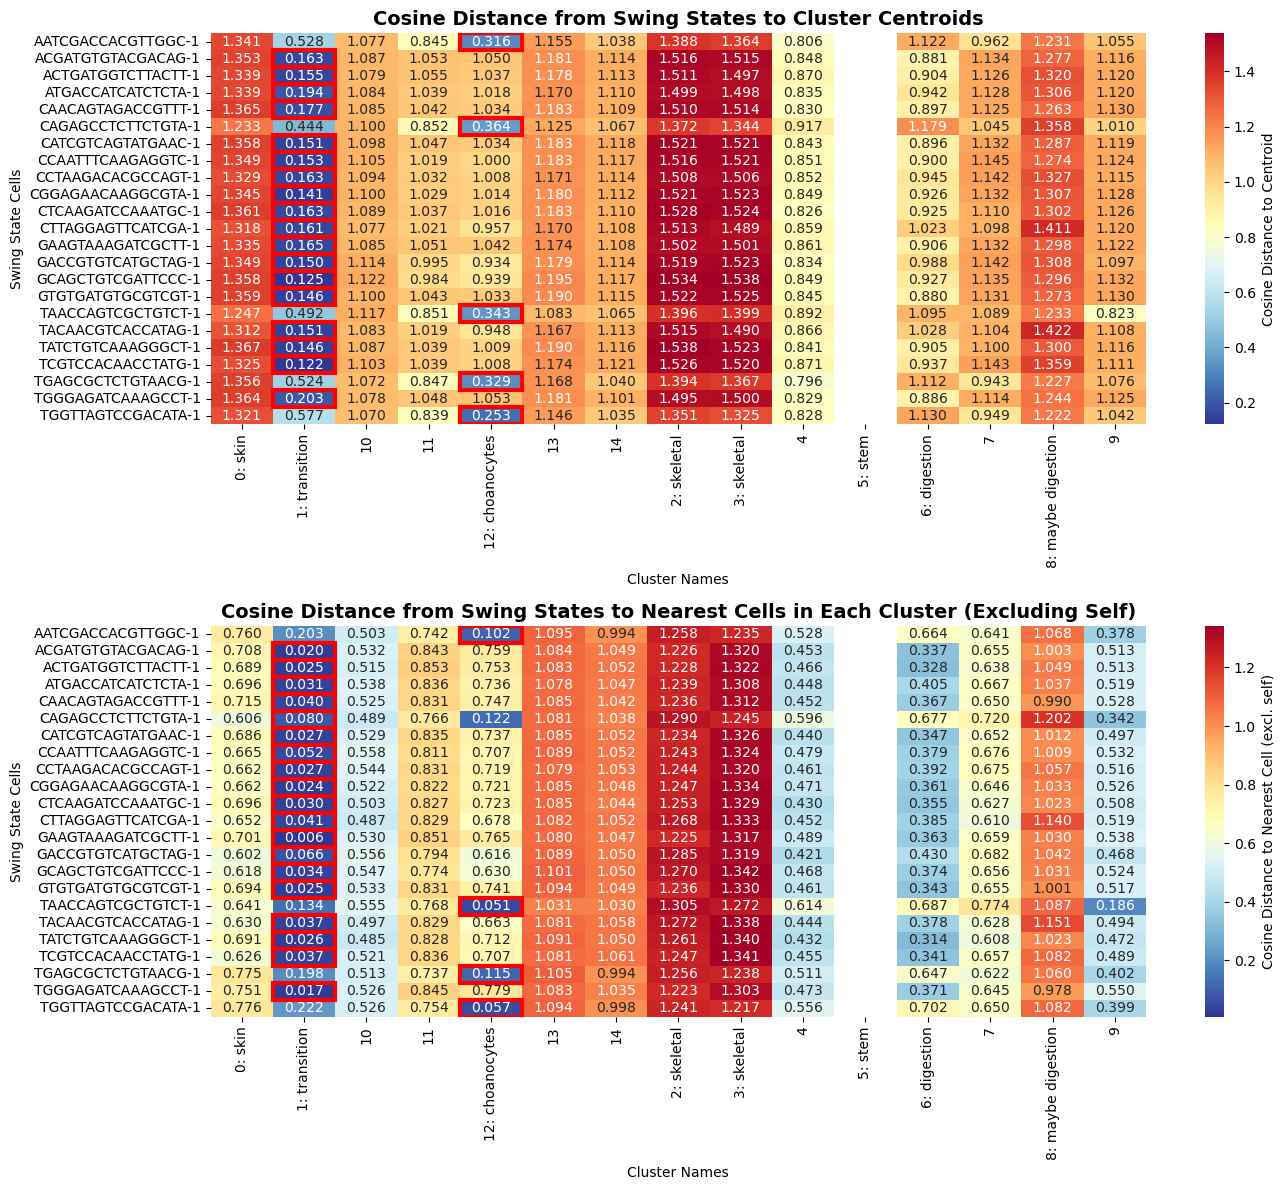


DISTANCE COMPARISON SUMMARY
           cell_id current_cluster closest_centroid centroid_distance closest_nearest_cell nearest_distance  same_prediction
AATCGACCACGTTGGC-1         5: stem  12: choanocytes             0.316      12: choanocytes            0.102             True
ACGATGTGTACGACAG-1         5: stem    1: transition             0.163        1: transition            0.020             True
ACTGATGGTCTTACTT-1         5: stem    1: transition             0.155        1: transition            0.025             True
ATGACCATCATCTCTA-1         5: stem    1: transition             0.194        1: transition            0.031             True
CAACAGTAGACCGTTT-1         5: stem    1: transition             0.177        1: transition            0.040             True
CAGAGCCTCTTCTGTA-1         5: stem  12: choanocytes             0.364        1: transition            0.080            False
CATCGTCAGTATGAAC-1         5: stem    1: transition             0.151        1: transition      

In [17]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_distances
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get swing states coordinates
swing_pca = swing_states.obsm['X_pca']
print(f"Analyzing {len(swing_states)} swing state cells")

# Get all clusters and their names
all_clusters = sorted(adata.obs['clusters'].unique())
cluster_names = {}
for cluster in all_clusters:
    # Get cluster name if available, otherwise use cluster number
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    if 'clusters_name' in adata.obs.columns:
        name = cluster_cells.obs['clusters_name'].iloc[0] if len(cluster_cells) > 0 else f"Cluster_{cluster}"
    else:
        name = f"Cluster_{cluster}"
    cluster_names[cluster] = name

print(f"Comparing to {len(all_clusters)} clusters")

# 1. CALCULATE DISTANCES TO CLUSTER CENTROIDS (EXCLUDING OWN CLUSTER)
print("Calculating distances to cluster centroids...")
centroid_distances = []

# Get cluster centroids
cluster_centroids = {}
for cluster in all_clusters:
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    centroid = np.mean(cluster_cells.obsm['X_pca'], axis=0)
    cluster_centroids[cluster] = centroid

for i, swing_cell_idx in enumerate(swing_states.obs_names):
    swing_coord = swing_pca[i].reshape(1, -1)
    swing_current_cluster = swing_states.obs.loc[swing_cell_idx, 'clusters']
    
    cell_distances = {'cell_id': swing_cell_idx}
    
    for cluster in all_clusters:
        if cluster == swing_current_cluster:
            # For own cluster, set NaN to exclude from heatmap
            cell_distances[cluster_names[cluster]] = np.nan
        else:
            centroid = cluster_centroids[cluster].reshape(1, -1)
            cosine_dist = cosine_distances(swing_coord, centroid)[0][0]
            cell_distances[cluster_names[cluster]] = cosine_dist
    
    centroid_distances.append(cell_distances)

centroid_df = pd.DataFrame(centroid_distances).set_index('cell_id')

# 2. CALCULATE DISTANCES TO NEAREST CELLS IN EACH CLUSTER (EXCLUDING SELF)
print("Calculating distances to nearest cells in each cluster (excluding self)...")
nearest_distances = []

for i, swing_cell_idx in enumerate(swing_states.obs_names):
    swing_coord = swing_pca[i].reshape(1, -1)
    swing_current_cluster = swing_states.obs.loc[swing_cell_idx, 'clusters']
    
    cell_distances = {'cell_id': swing_cell_idx}
    
    for cluster in all_clusters:
        if cluster == swing_current_cluster:
            # For own cluster, set NaN to exclude from heatmap visualization
            cell_distances[cluster_names[cluster]] = np.nan
        else:
            cluster_cells = adata[adata.obs['clusters'] == cluster]
            cluster_coords = cluster_cells.obsm['X_pca']
            
            # Calculate distances to ALL cells in this OTHER cluster
            distances_to_cluster = cosine_distances(swing_coord, cluster_coords)[0]
            
            # Take the minimum distance (closest cell)
            min_distance = np.min(distances_to_cluster)
            cell_distances[cluster_names[cluster]] = min_distance
    
    nearest_distances.append(cell_distances)

nearest_df = pd.DataFrame(nearest_distances).set_index('cell_id')

# 3. CREATE HEATMAPS
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, max(12, len(swing_states)//2)))

# Heatmap 1: Distances to Cluster Centroids
print("Creating centroid distances heatmap...")
sns.heatmap(centroid_df, annot=True, fmt='.3f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Cosine Distance to Centroid'}, ax=ax1)
ax1.set_title('Cosine Distance from Swing States to Cluster Centroids', fontweight='bold', fontsize=14)
ax1.set_xlabel('Cluster Names')
ax1.set_ylabel('Swing State Cells')

# Highlight minimum distances with red borders for centroid heatmap (excluding NaN values)
for i, cell_id in enumerate(centroid_df.index):
    row_data = centroid_df.iloc[i].dropna()  # Remove NaN values (own cluster)
    if len(row_data) > 0:
        min_cluster = row_data.idxmin()
        min_idx = list(centroid_df.columns).index(min_cluster)
        ax1.add_patch(plt.Rectangle((min_idx, i), 1, 1, fill=False, edgecolor='red', lw=3))

# Heatmap 2: Distances to Nearest Cells (Excluding Self)
print("Creating nearest cell distances heatmap...")
sns.heatmap(nearest_df, annot=True, fmt='.3f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Cosine Distance to Nearest Cell (excl. self)'}, ax=ax2)
ax2.set_title('Cosine Distance from Swing States to Nearest Cells in Each Cluster (Excluding Self)', fontweight='bold', fontsize=14)
ax2.set_xlabel('Cluster Names')
ax2.set_ylabel('Swing State Cells')

# Highlight minimum distances with red borders for nearest cell heatmap (excluding NaN values)
for i, cell_id in enumerate(nearest_df.index):
    row_data = nearest_df.iloc[i].dropna()  # Remove NaN values (own cluster)
    if len(row_data) > 0:
        min_cluster = row_data.idxmin()
        min_idx = list(nearest_df.columns).index(min_cluster)
        ax2.add_patch(plt.Rectangle((min_idx, i), 1, 1, fill=False, edgecolor='red', lw=3))

plt.tight_layout()
plt.show()

# 4. COMPARISON SUMMARY
print("\n" + "="*100)
print("DISTANCE COMPARISON SUMMARY")
print("="*100)

comparison_data = []
for cell_id in centroid_df.index:
    current_cluster = swing_states.obs.loc[cell_id, 'clusters']
    current_cluster_name = cluster_names[current_cluster]
    
    centroid_min = centroid_df.loc[cell_id].idxmin()
    centroid_min_dist = centroid_df.loc[cell_id].min()
    
    # For nearest cell, exclude NaN values (own cluster)
    nearest_row = nearest_df.loc[cell_id].dropna()
    if len(nearest_row) > 0:
        nearest_min = nearest_row.idxmin()
        nearest_min_dist = nearest_row.min()
    else:
        nearest_min = "No other clusters"
        nearest_min_dist = np.nan
    
    comparison_data.append({
        'cell_id': cell_id,
        'current_cluster': current_cluster_name,
        'closest_centroid': centroid_min,
        'centroid_distance': f"{centroid_min_dist:.3f}",
        'closest_nearest_cell': nearest_min,
        'nearest_distance': f"{nearest_min_dist:.3f}" if not np.isnan(nearest_min_dist) else "N/A",
        'same_prediction': centroid_min == nearest_min
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

same_predictions = comparison_df['same_prediction'].sum()
total_predictions = len(comparison_df)
print(f"\nAgreement between methods: {same_predictions}/{total_predictions} ({same_predictions/total_predictions*100:.1f}%)")

print(f"\nCells that should be reclassified (closest to different cluster):")
reclassify_centroid = comparison_df[comparison_df['current_cluster'] != comparison_df['closest_centroid']]
# Filter out cells where nearest_distance is N/A for the reclassification count
reclassify_nearest = comparison_df[(comparison_df['current_cluster'] != comparison_df['closest_nearest_cell']) & 
                                 (comparison_df['nearest_distance'] != 'N/A')]
print(f"Based on centroids: {len(reclassify_centroid)}/{len(comparison_df)} cells")
print(f"Based on nearest cells: {len(reclassify_nearest)}/{len(comparison_df)} cells")

# Evaluating other spaces with umap and pca

In [18]:
# Hierarchical validation across scales
spaces = {
    'pca': adata.obsm['X_pca'],
    'umap': adata.obsm['X_umap'], 
    'hvg': adata[:, adata.var['highly_variable']].X,
    #'markers': adata[:, marker_genes].X,
    'ct_corr': adata[:, adata.var['ct_correlates']].X
}

for space_name, coordinates in spaces.items():
    sil_scores = silhouette_samples(coordinates, adata.obs['clusters'])
    print(f"{space_name}: avg={np.mean(sil_scores):.3f}")

pca: avg=0.373
umap: avg=0.428
hvg: avg=0.325
ct_corr: avg=0.202


/Users/miki/micromamba/envs/retreat/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/vl/q52ljx6j7yj6w2b54wlmdmb80000gn/T/ipykernel_16029/1475057315.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.5, key_added='clusters_umap')


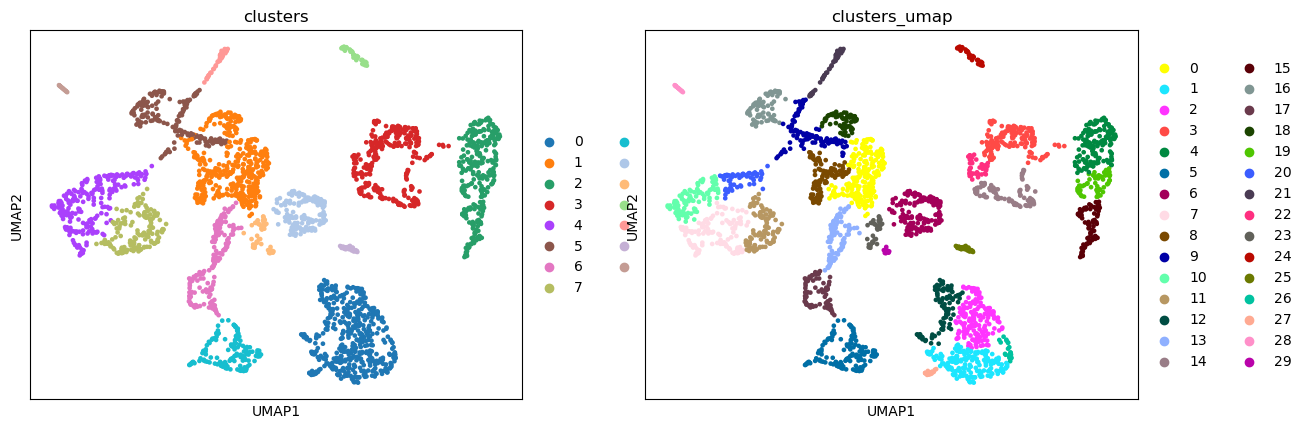

Old clustering silhouette: 0.428
New clustering silhouette: 0.394


In [19]:
# Use UMAP coordinates for clustering
sc.pp.neighbors(adata, use_rep='X_umap', n_neighbors=15)
sc.tl.leiden(adata, resolution=0.5, key_added='clusters_umap')

# Compare old vs new clustering
sc.pl.umap(adata, color=['clusters', 'clusters_umap'], ncols=2)

# Check silhouette scores
from sklearn.metrics import silhouette_score
old_sil = silhouette_score(adata.obsm['X_umap'], adata.obs['clusters'])
new_sil = silhouette_score(adata.obsm['X_umap'], adata.obs['clusters_umap'])

print(f"Old clustering silhouette: {old_sil:.3f}")
print(f"New clustering silhouette: {new_sil:.3f}")

In [20]:
# Test different resolutions
for res in [0.1, 0.3, 0.5, 0.8, 1.0]:
    sc.tl.leiden(adata, resolution=res, key_added=f'clusters_umap_{res}')
    sil = silhouette_score(adata.obsm['X_umap'], adata.obs[f'clusters_umap_{res}'])
    print(f"Resolution {res}: silhouette = {sil:.3f}")

Resolution 0.1: silhouette = 0.402
Resolution 0.3: silhouette = 0.415
Resolution 0.5: silhouette = 0.394
Resolution 0.8: silhouette = 0.402
Resolution 1.0: silhouette = 0.420


In [21]:
print("Number of clusters:")
print(f"Original PCA: {len(adata.obs['clusters'].unique())} clusters")
print(f"UMAP (res=0.3): {len(adata.obs['clusters_umap_0.3'].unique())} clusters") 
print(f"UMAP (res=0.5): {len(adata.obs['clusters_umap'].unique())} clusters")

# Look at cluster sizes
print("\nOriginal cluster sizes:")
print(adata.obs['clusters'].value_counts().sort_index())
print("\nUMAP cluster sizes (res=0.3):")
print(adata.obs['clusters_umap_0.3'].value_counts().sort_index())

Number of clusters:
Original PCA: 15 clusters
UMAP (res=0.3): 25 clusters
UMAP (res=0.5): 30 clusters

Original cluster sizes:
clusters
0     480
1     409
2     293
3     282
4     235
5     178
6     168
7     153
8     148
9     142
10     52
11     38
12     38
13     30
14     16
Name: count, dtype: int64

UMAP cluster sizes (res=0.3):
clusters_umap_0.3
0     237
1     226
2     216
3     212
4     175
5     173
6     155
7     154
8     148
9     142
10    108
11     91
12     88
13     81
14     79
15     77
16     60
17     48
18     40
19     39
20     38
21     30
22     17
23     16
24     12
Name: count, dtype: int64


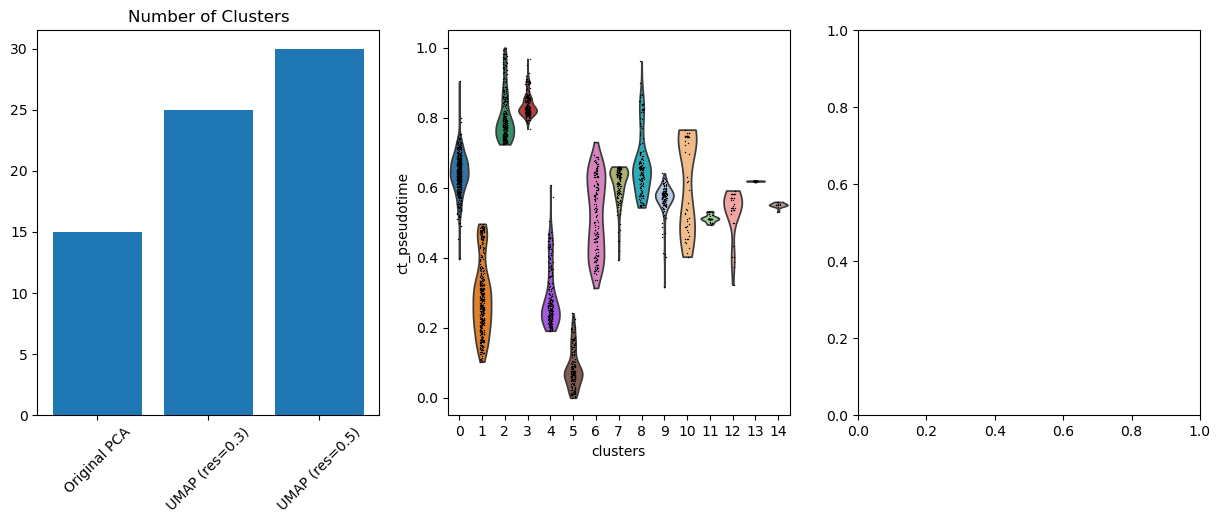

<Figure size 640x480 with 0 Axes>

In [22]:
# Compare cluster counts and pseudotime distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Number of clusters
methods = ['Original PCA', 'UMAP (res=0.3)', 'UMAP (res=0.5)']
n_clusters = [
    len(adata.obs['clusters'].unique()),
    len(adata.obs['clusters_umap_0.3'].unique()),
    len(adata.obs['clusters_umap'].unique())
]
axes[0].bar(methods, n_clusters)
axes[0].set_title('Number of Clusters')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Pseudotime distribution by clustering method
sc.pl.violin(adata, keys='ct_pseudotime', groupby='clusters', ax=axes[1])
axes[1].set_title('Pseudotime - Original Clustering')

sc.pl.violin(adata, keys='ct_pseudotime', groupby='clusters_umap_0.3', ax=axes[2])
axes[2].set_title('Pseudotime - UMAP Clustering')

plt.tight_layout()
plt.show()

In [23]:
# Analyze Cluster 1 (transition cells) - the interesting one
cluster_1_cells = adata[adata.obs['clusters'] == '1']
print("Cluster 1 (Transition cells) Analysis:")
print(f"Size: {len(cluster_1_cells)} cells")
print(f"Pseudotime range: {cluster_1_cells.obs['ct_pseudotime'].min():.3f} - {cluster_1_cells.obs['ct_pseudotime'].max():.3f}")
print(f"Pseudotime mean: {cluster_1_cells.obs['ct_pseudotime'].mean():.3f} ± {cluster_1_cells.obs['ct_pseudotime'].std():.3f}")

# See how UMAP splits the transition cluster
print(f"\nHow UMAP clustering splits Cluster 1 (transition):")
transition_umap = adata[adata.obs['clusters'] == '1'].obs['clusters_umap_0.3'].value_counts().sort_index()
print(transition_umap)

print("\n" + "="*50)

# Analyze Cluster 5 (potential stem cells)  
cluster_5_cells = adata[adata.obs['clusters'] == '5']
print("Cluster 5 (Potential stem cells) Analysis:")
print(f"Size: {len(cluster_5_cells)} cells")
print(f"Pseudotime range: {cluster_5_cells.obs['ct_pseudotime'].min():.3f} - {cluster_5_cells.obs['ct_pseudotime'].max():.3f}")
print(f"Pseudotime mean: {cluster_5_cells.obs['ct_pseudotime'].mean():.3f} ± {cluster_5_cells.obs['ct_pseudotime'].std():.3f}")

# See how UMAP splits the potential stem cluster
print(f"\nHow UMAP clustering splits Cluster 5 (potential stem):")
stem_umap = adata[adata.obs['clusters'] == '5'].obs['clusters_umap_0.3'].value_counts().sort_index()
print(stem_umap)

Cluster 1 (Transition cells) Analysis:
Size: 409 cells
Pseudotime range: 0.103 - 0.497
Pseudotime mean: 0.289 ± 0.106

How UMAP clustering splits Cluster 1 (transition):
clusters_umap_0.3
2     215
4      86
10    108
Name: count, dtype: int64

Cluster 5 (Potential stem cells) Analysis:
Size: 178 cells
Pseudotime range: 0.000 - 0.241
Pseudotime mean: 0.083 ± 0.055

How UMAP clustering splits Cluster 5 (potential stem):
clusters_umap_0.3
4     89
14    79
17    10
Name: count, dtype: int64


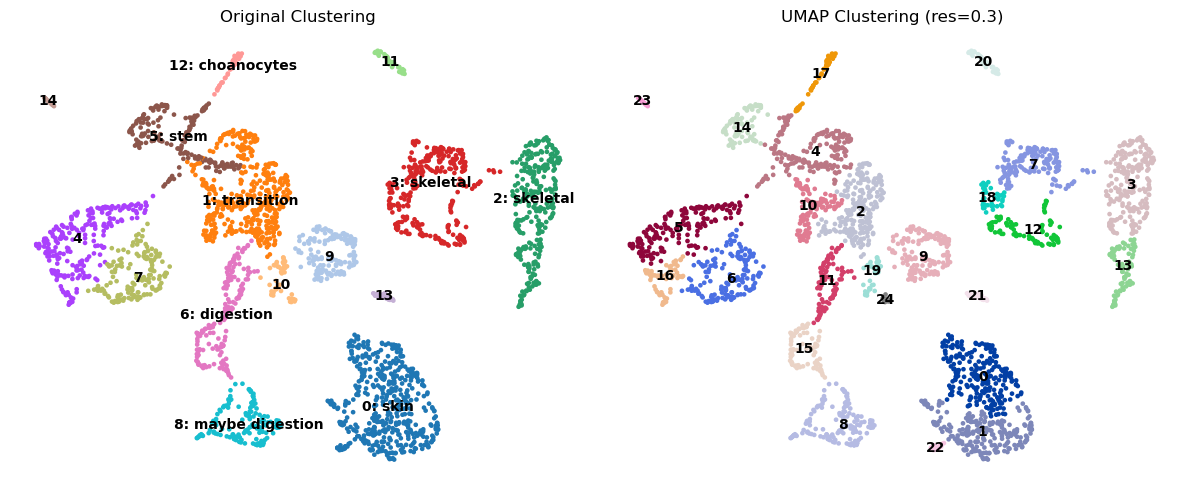

Data type check:
clusters column type: category
clusters_umap_0.3 column type: category

Sample values:
Original clusters: AAACCCAAGGACAGCT-1    3
AAACCCAAGGGTTTCT-1    0
AAACCCACAAATGGTA-1    2
AAACCCATCGAGAAGC-1    8
AAACCCATCTTGTTAC-1    3
Name: clusters, dtype: category
Categories (15, object): ['0', '1', '2', '3', ..., '11', '12', '13', '14']
UMAP clusters: AAACCCAAGGACAGCT-1     7
AAACCCAAGGGTTTCT-1     1
AAACCCACAAATGGTA-1    13
AAACCCATCGAGAAGC-1     8
AAACCCATCTTGTTAC-1     7
Name: clusters_umap_0.3, dtype: category
Categories (25, object): ['0', '1', '2', '3', ..., '21', '22', '23', '24']


In [24]:
# Let's check this visually and verify the numbers match
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Original clustering
sc.pl.umap(adata, color='clusters_name', ax=axes[0], show=False, frameon=False, legend_loc='on data')
axes[0].set_title('Original Clustering')

# Plot 2: UMAP clustering  
sc.pl.umap(adata, color='clusters_umap_0.3', ax=axes[1], show=False, frameon=False, legend_loc='on data')
axes[1].set_title('UMAP Clustering (res=0.3)')

plt.tight_layout()
plt.show()

# Let's also double-check the data types and make sure we're comparing correctly
print("Data type check:")
print(f"clusters column type: {adata.obs['clusters'].dtype}")
print(f"clusters_umap_0.3 column type: {adata.obs['clusters_umap_0.3'].dtype}")

print(f"\nSample values:")
print(f"Original clusters: {adata.obs['clusters'].head()}")
print(f"UMAP clusters: {adata.obs['clusters_umap_0.3'].head()}")

# Highest Silhouette Result

In [25]:
# Create synthetic "ideal" cells
cluster_ideals = {}

for cluster in adata.obs['clusters'].unique():
    cluster_cells = adata[adata.obs['clusters'] == cluster]
    
    # Method 1: Mean of high-silhouette cells only
    high_sil_cells = cluster_cells[cluster_cells.obs['silhouette_score'] > 0.3]
    ideal_coords = np.mean(high_sil_cells.obsm['X_pca'], axis=0)
    
    # Method 2: Weighted mean (weight by silhouette score)
    weights = cluster_cells.obs['silhouette_score'].values
    weighted_coords = np.average(cluster_cells.obsm['X_pca'], axis=0, weights=weights)
    
    cluster_ideals[cluster] = {
        'mean_coords': ideal_coords,
        'weighted_coords': weighted_coords
    }

/Users/miki/micromamba/envs/retreat/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3858: RuntimeWarning: Mean of empty slice.
  return mean(axis=axis, dtype=dtype, out=out, **kwargs)
/Users/miki/micromamba/envs/retreat/lib/python3.13/site-packages/numpy/_core/_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [27]:
# For each swing state, find which cluster ideal it's closest to
swing_trajectories = []

for swing_cell in swing_states.obs_names:
    swing_coords = swing_states[swing_states.obs_names == swing_cell].obsm['X_pca'][0]
    current_cluster = swing_states.obs.loc[swing_cell, 'clusters']
    
    distances_to_ideals = {}
    for cluster, ideal_data in cluster_ideals.items():
        if cluster != current_cluster:  # Exclude own cluster
            distance = cosine_distances(swing_coords.reshape(1,-1), 
                                     ideal_data['weighted_coords'].reshape(1,-1))[0][0]
            distances_to_ideals[cluster] = distance
    
    # Find closest OTHER cluster ideal
    target_cluster = min(distances_to_ideals, key=distances_to_ideals.get)
    target_distance = distances_to_ideals[target_cluster]
    
    swing_trajectories.append({
        'cell_id': swing_cell,
        'current_cluster': current_cluster,
        'target_cluster': target_cluster,
        'distance_to_target': target_distance,
        'trajectory': f"{current_cluster} → {target_cluster}"
    })

trajectory_df = pd.DataFrame(swing_trajectories)
print("Developmental Trajectories:")
print(trajectory_df.groupby('trajectory').size().sort_values(ascending=False))

Developmental Trajectories:
trajectory
5 → 1     18
5 → 12     5
dtype: int64


---

In [37]:
#swing_states = adata[(adata.obs['silhouette_score'] <= 0.0) & (adata.obs['clusters'] == origin_cluster)]
swing_states = adata[(adata.obs['silhouette_score'] <= 0.0)]

def calculate_transition_probabilities(swing_cell, cluster_ideals):
    swing_coords = swing_states[swing_states.obs_names == swing_cell].obsm['X_pca'][0]
    current_cluster = swing_states.obs.loc[swing_cell, 'clusters']
    
    # Calculate distances to all OTHER cluster ideals
    distances = {}
    for cluster, ideal_data in cluster_ideals.items():
        if cluster != current_cluster:
            # Access the coordinate array from the dictionary
            ideal_coords = ideal_data['weighted_coords']  # or 'mean_coords'
            dist = cosine_distances(swing_coords.reshape(1,-1), 
                                 ideal_coords.reshape(1,-1))[0][0]
            distances[cluster] = dist
    
    # Convert distances to similarities (closer = higher similarity)
    similarities = {k: 1/(1+v) for k, v in distances.items()}
    
    # Convert to probabilities (sum = 100%)
    total_sim = sum(similarities.values())
    probabilities = {k: (v/total_sim)*100 for k, v in similarities.items()}
    
    return probabilities

# Apply to all swing states
transition_analysis = []
for swing_cell in swing_states.obs_names:
    probs = calculate_transition_probabilities(swing_cell, cluster_ideals)
    
    # Find top 3 most likely destinations
    sorted_probs = sorted(probs.items(), key=lambda x: x[1], reverse=True)[:3]
    
    transition_analysis.append({
        'cell_id': swing_cell,
        'current_cluster': swing_states.obs.loc[swing_cell, 'clusters'],
        'most_likely_target': sorted_probs[0][0],
        'probability_1st': f"{sorted_probs[0][1]:.1f}%",
        'probability_2nd': f"{sorted_probs[1][1]:.1f}%",
        'probability_3rd': f"{sorted_probs[2][1]:.1f}%",
        'target_1st': sorted_probs[0][0],
        'target_2nd': sorted_probs[1][0],
        'target_3rd': sorted_probs[2][0]
    })

transition_df = pd.DataFrame(transition_analysis)
print("Transition Probability Analysis:")
print(transition_df)

Transition Probability Analysis:
               cell_id current_cluster most_likely_target probability_1st  \
0   AAAGGTACAAATGGTA-1              10                  3            9.6%   
1   AACAAAGGTGTGTACT-1               6                  1           10.4%   
2   AAGTTCGCATACCGTA-1              10                  3           10.0%   
3   AATCGACCACGTTGGC-1               5                 12           10.4%   
4   ACAACCATCCTCAGGG-1              10                  3            9.5%   
5   ACCAACACATGACGGA-1               4                  7           11.2%   
6   ACGATGTGTACGACAG-1               5                  1           12.0%   
7   ACTGATGGTCTTACTT-1               5                  1           12.1%   
8   ACTTATCGTAGAAACT-1               1                  5           12.1%   
9   AGAAGTAGTCGATGCC-1               1                  5           11.9%   
10  AGCGTATCAGCTGTGC-1               4                  7           10.5%   
11  AGGCATTAGCGCCGTT-1               4     

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

def build_gene_prediction_model(adata, n_genes=50):
    # Get expression data and cluster labels
    X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X
    y = adata.obs['clusters']
    
    # Train Random Forest to predict cluster from gene expression
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X, y)
    
    # Get feature importance (which genes are most predictive)
    gene_importance = pd.DataFrame({
        'gene': adata.var_names,
        'importance': rf.feature_importances_
    }).sort_values('importance', ascending=False)
    
    # Get top predictive genes per cluster
    cluster_signatures = {}
    for cluster in adata.obs['clusters'].unique():
        # Train model to predict this cluster vs all others
        y_binary = (y == cluster).astype(int)
        rf_binary = RandomForestClassifier(n_estimators=100, random_state=42)
        rf_binary.fit(X, y_binary)
        
        # Get top genes for this cluster
        cluster_genes = pd.DataFrame({
            'gene': adata.var_names,
            'importance': rf_binary.feature_importances_
        }).sort_values('importance', ascending=False).head(n_genes)
        
        cluster_signatures[cluster] = {
            'top_genes': cluster_genes['gene'].tolist(),
            'importances': cluster_genes['importance'].tolist()
        }
    
    return rf, gene_importance, cluster_signatures

# Build the model
rf_model, gene_rankings, cluster_gene_signatures = build_gene_prediction_model(adata)

# Predict probabilities for swing states
swing_gene_predictions = []
for swing_cell in swing_states.obs_names:
    cell_expression = swing_states[swing_states.obs_names == swing_cell].X.toarray().flatten()
    
    # Get prediction probabilities for all clusters
    probs = rf_model.predict_proba(cell_expression.reshape(1, -1))[0]
    cluster_labels = rf_model.classes_
    
    # Create probability dict
    prob_dict = dict(zip(cluster_labels, probs * 100))
    
    # Find top predictions
    sorted_preds = sorted(prob_dict.items(), key=lambda x: x[1], reverse=True)[:3]
    
    swing_gene_predictions.append({
        'cell_id': swing_cell,
        'current_cluster': swing_states.obs.loc[swing_cell, 'clusters'],
        'gene_pred_1st': sorted_preds[0][0],
        'gene_prob_1st': f"{sorted_preds[0][1]:.1f}%",
        'gene_pred_2nd': sorted_preds[1][0], 
        'gene_prob_2nd': f"{sorted_preds[1][1]:.1f}%",
        'gene_pred_3rd': sorted_preds[2][0],
        'gene_prob_3rd': f"{sorted_preds[2][1]:.1f}%"
    })

Gene-Based Cluster Predictions:
              cell_id current_cluster gene_pred_1st gene_prob_1st  \
0  AAAGGTACAAATGGTA-1              10            10         95.0%   
1  AACAAAGGTGTGTACT-1               6             6         79.0%   
2  AAGTTCGCATACCGTA-1              10            10         96.0%   
3  AATCGACCACGTTGGC-1               5             5         96.0%   
4  ACAACCATCCTCAGGG-1              10            10         99.0%   

  gene_pred_2nd gene_prob_2nd gene_pred_3rd gene_prob_3rd  
0             3          2.0%             1          1.0%  
1             1         17.0%            10          2.0%  
2             3          4.0%             0          0.0%  
3            10          1.0%            12          1.0%  
4             1          1.0%             0          0.0%  


In [39]:
gene_pred_df = pd.DataFrame(swing_gene_predictions)
print("Gene-Based Cluster Predictions:")
print(gene_pred_df)

Gene-Based Cluster Predictions:
               cell_id current_cluster gene_pred_1st gene_prob_1st  \
0   AAAGGTACAAATGGTA-1              10            10         95.0%   
1   AACAAAGGTGTGTACT-1               6             6         79.0%   
2   AAGTTCGCATACCGTA-1              10            10         96.0%   
3   AATCGACCACGTTGGC-1               5             5         96.0%   
4   ACAACCATCCTCAGGG-1              10            10         99.0%   
5   ACCAACACATGACGGA-1               4             4         88.0%   
6   ACGATGTGTACGACAG-1               5             5         87.0%   
7   ACTGATGGTCTTACTT-1               5             5         80.0%   
8   ACTTATCGTAGAAACT-1               1             1         84.0%   
9   AGAAGTAGTCGATGCC-1               1             1         91.0%   
10  AGCGTATCAGCTGTGC-1               4             4         92.0%   
11  AGGCATTAGCGCCGTT-1               4             4         89.0%   
12  AGGCATTGTGTGATGG-1              10            10      

In [36]:
# Show top predictive genes for each cluster
print("\nCLUSTER GENE SIGNATURES:")
print("="*50)
for cluster, signature in cluster_gene_signatures.items():
    print(f"\nCluster {cluster} signature genes:")
    top_5_genes = signature['top_genes'][:5]
    top_5_scores = signature['importances'][:5]
    
    for gene, score in zip(top_5_genes, top_5_scores):
        print(f"  {gene}: {score:.3f} importance")

# Compare spatial vs genetic predictions
combined_analysis = pd.merge(transition_df, gene_pred_df, on='cell_id', suffixes=('_spatial', '_genetic'))
print("\nSPATIAL vs GENETIC PREDICTIONS:")
print("="*50)
print(combined_analysis[['cell_id', 'target_1st', 'gene_pred_1st', 'probability_1st', 'gene_prob_1st']])

# Agreement analysis
agreement = (combined_analysis['target_1st'] == combined_analysis['gene_pred_1st']).mean()
print(f"\nAgreement between spatial and genetic predictions: {agreement:.1%}")


CLUSTER GENE SIGNATURES:

Cluster 3 signature genes:
  SUB4.g5682: 0.018 importance
  SUB4.g13838: 0.018 importance
  SUB4.g16515: 0.017 importance
  SUB4.g6885: 0.016 importance
  SUB4.g18705: 0.015 importance

Cluster 0 signature genes:
  SUB4.g11102: 0.029 importance
  SUB4.g15823: 0.027 importance
  SUB4.g19250: 0.020 importance
  SUB4.g3720: 0.020 importance
  SUB4.g14846: 0.019 importance

Cluster 2 signature genes:
  SUB4.g8882: 0.021 importance
  SUB4.g17774: 0.020 importance
  SUB4.g670: 0.020 importance
  SUB4.g9689: 0.020 importance
  SUB4.g18167: 0.019 importance

Cluster 8 signature genes:
  SUB4.g6792: 0.030 importance
  SUB4.g14315: 0.024 importance
  SUB4.g2516: 0.022 importance
  SUB4.g4273: 0.021 importance
  SUB4.g6122: 0.020 importance

Cluster 9 signature genes:
  SUB4.g4000: 0.020 importance
  SUB4.g15785: 0.020 importance
  SUB4.g20140: 0.019 importance
  SUB4.g2631: 0.018 importance
  SUB4.g18569: 0.017 importance

Cluster 5 signature genes:
  SUB4.g2710: 0.018